<a href="https://colab.research.google.com/github/rwalden-gif/IntroToML/blob/main/Homework5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
url = "https://raw.githubusercontent.com/rwalden-gif/IntroToML/main/Housing.csv"
epochs = 5000
learning_rates = [0.1, 0.01, 0.001, 0.0001]

In [2]:
t_c = torch.tensor([0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0])
t_u = torch.tensor([35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4])
t_un = 0.1 * t_u
def linear_model(t, w, b):
  return w * t + b
def quad_model(t, w2, w1, b):
  return w2 * t ** 2 + w1 * t + b
def loss_fn(t_p, t_c):
  return ((t_p - t_c) ** 2).mean()

In [3]:
def train(model, start, lr):
    params = torch.tensor(start, requires_grad=True)
    losses = []
    for epoch in range(1, epochs + 1):
        loss = loss_fn(model(t_un, *params), t_c)
        loss.backward()
        with torch.no_grad():
            params -= lr * params.grad
        params.grad.zero_()
        if epoch % 500 == 0:
            losses.append(loss.item())
    return params.detach(), losses

In [4]:
best_loss = 1e9
for lr in learning_rates:
    params, losses = train(quad_model, [0.0, 1.0, 0.0], lr)
    print("Nonlinear model, learning rate", lr)
    for i, loss in enumerate(losses):
        print("  epoch", (i + 1) * 500, "loss", loss)
    if losses[-1] < best_loss:
        best_loss = losses[-1]
        best_lr = lr
        best_params = params

Nonlinear model, learning rate 0.1
  epoch 500 loss nan
  epoch 1000 loss nan
  epoch 1500 loss nan
  epoch 2000 loss nan
  epoch 2500 loss nan
  epoch 3000 loss nan
  epoch 3500 loss nan
  epoch 4000 loss nan
  epoch 4500 loss nan
  epoch 5000 loss nan
Nonlinear model, learning rate 0.01
  epoch 500 loss nan
  epoch 1000 loss nan
  epoch 1500 loss nan
  epoch 2000 loss nan
  epoch 2500 loss nan
  epoch 3000 loss nan
  epoch 3500 loss nan
  epoch 4000 loss nan
  epoch 4500 loss nan
  epoch 5000 loss nan
Nonlinear model, learning rate 0.001
  epoch 500 loss nan
  epoch 1000 loss nan
  epoch 1500 loss nan
  epoch 2000 loss nan
  epoch 2500 loss nan
  epoch 3000 loss nan
  epoch 3500 loss nan
  epoch 4000 loss nan
  epoch 4500 loss nan
  epoch 5000 loss nan
Nonlinear model, learning rate 0.0001
  epoch 500 loss 11.628111839294434
  epoch 1000 loss 9.293487548828125
  epoch 1500 loss 7.631711006164551
  epoch 2000 loss 6.4485392570495605
  epoch 2500 loss 5.6058149337768555
  epoch 3000 lo

In [5]:
linear_params, linear_losses = train(linear_model, [1.0, 0.0], 0.01)
print("Linear model, learning rate 0.01")
for i, loss in enumerate(linear_losses):
    print("  epoch", (i + 1) * 500, "loss", loss)

print("Best nonlinear learning rate:", best_lr)
print("Nonlinear final loss:", best_loss)
print("Linear final loss:", linear_losses[-1])

Linear model, learning rate 0.01
  epoch 500 loss 7.860115051269531
  epoch 1000 loss 3.828537940979004
  epoch 1500 loss 3.092191219329834
  epoch 2000 loss 2.957697868347168
  epoch 2500 loss 2.933133840560913
  epoch 3000 loss 2.9286484718322754
  epoch 3500 loss 2.9278297424316406
  epoch 4000 loss 2.9276793003082275
  epoch 4500 loss 2.927651882171631
  epoch 5000 loss 2.9276468753814697
Best nonlinear learning rate: 0.0001
Nonlinear final loss: 3.8959767818450928
Linear final loss: 2.9276468753814697


Lowest loss a quadratic can reach: 2.0907201766967773


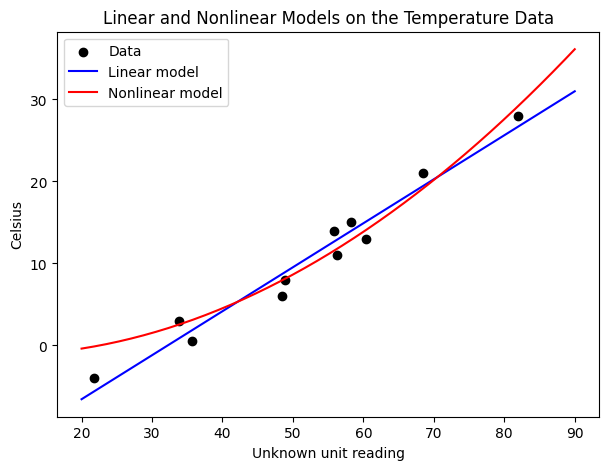

In [6]:
A = torch.stack([t_un ** 2, t_un, torch.ones(11)], dim=1)
best_fit = torch.linalg.lstsq(A, t_c.unsqueeze(1)).solution.squeeze()
print("Lowest loss a quadratic can reach:", loss_fn(A @ best_fit, t_c).item())

t_range = torch.linspace(20, 90, 200)
plt.figure(figsize=(7, 5))
plt.scatter(t_u, t_c, color="black", label="Data")
plt.plot(t_range, linear_model(0.1 * t_range, *linear_params), color="blue", label="Linear model")
plt.plot(t_range, quad_model(0.1 * t_range, *best_params), color="red", label="Nonlinear model")
plt.xlabel("Unknown unit reading")
plt.ylabel("Celsius")
plt.title("Linear and Nonlinear Models on the Temperature Data")
plt.legend()
plt.show()

In [7]:
df = pd.read_csv(url)
for col in ["mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "prefarea"]:
    df[col] = (df[col] == "yes").astype(int)
df = pd.get_dummies(df, columns=["furnishingstatus"], drop_first=True, dtype=int)

df = df.sample(frac=1, random_state=42)
split = int(0.8 * len(df))
train_df = df[:split]
val_df = df[split:]
print("Training rows:", len(train_df), "Validation rows:", len(val_df))

def prepare(columns):
    X_train = torch.tensor(train_df[columns].values, dtype=torch.float32)
    X_val = torch.tensor(val_df[columns].values, dtype=torch.float32)
    mean = X_train.mean(0)
    std = X_train.std(0, unbiased=False)
    y_train = torch.tensor(train_df["price"].values, dtype=torch.float32)
    y_val = torch.tensor(val_df["price"].values, dtype=torch.float32)
    return (X_train - mean) / std, (X_val - mean) / std, y_train, y_val

Training rows: 436 Validation rows: 109


In [8]:
def train_housing(X_train, X_val, y_train, y_val, lr):
    w = torch.zeros(X_train.shape[1], requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    train_curve, val_curve, log = [], [], []
    for epoch in range(1, epochs + 1):
        loss = 0.5 * ((X_train @ w + b - y_train) ** 2).mean()
        loss.backward()
        with torch.no_grad():
            w -= lr * w.grad
            b -= lr * b.grad
            val_pred = X_val @ w + b
            val_loss = 0.5 * ((val_pred - y_val) ** 2).mean()
            r2 = 1 - ((y_val - val_pred) ** 2).sum() / ((y_val - y_val.mean()) ** 2).sum()
        w.grad.zero_()
        b.grad.zero_()
        train_curve.append(loss.item())
        val_curve.append(val_loss.item())
        if epoch % 500 == 0:
            log.append((epoch, loss.item(), val_loss.item(), r2.item()))
    return train_curve, val_curve, log

In [9]:
columns = ["area", "bedrooms", "bathrooms", "stories", "parking"]
print("Inputs:", columns)
X_train, X_val, y_train, y_val = prepare(columns)

best_val = 1e30
for lr in learning_rates:
    train_curve, val_curve, log = train_housing(X_train, X_val, y_train, y_val, lr)
    print()
    print("Learning rate", lr)
    print("  epoch   train loss     validation loss   validation R2")
    for epoch, tl, vl, r2 in log:
        print(f"  {epoch:5d}   {tl:.4e}   {vl:.4e}      {r2:.4f}")
    if log[-1][2] < best_val:
        best_val = log[-1][2]
        best_lr = lr
        best_log = log
        best_train_curve = train_curve
        best_val_curve = val_curve

print()
print("Best learning rate:", best_lr)
print("Final train loss:", best_log[-1][1])
print("Final validation loss:", best_log[-1][2])
print("Final validation R2:", best_log[-1][3])

Inputs: ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']

Learning rate 0.1
  epoch   train loss     validation loss   validation R2
    500   7.5754e+11   8.0966e+11      0.5389
   1000   7.5754e+11   8.0966e+11      0.5389
   1500   7.5754e+11   8.0966e+11      0.5389
   2000   7.5754e+11   8.0966e+11      0.5389
   2500   7.5754e+11   8.0966e+11      0.5389
   3000   7.5754e+11   8.0966e+11      0.5389
   3500   7.5754e+11   8.0966e+11      0.5389
   4000   7.5754e+11   8.0966e+11      0.5389
   4500   7.5754e+11   8.0966e+11      0.5389
   5000   7.5754e+11   8.0966e+11      0.5389

Learning rate 0.01
  epoch   train loss     validation loss   validation R2
    500   7.5819e+11   8.1644e+11      0.5351
   1000   7.5754e+11   8.0967e+11      0.5389
   1500   7.5754e+11   8.0966e+11      0.5389
   2000   7.5754e+11   8.0967e+11      0.5389
   2500   7.5754e+11   8.0967e+11      0.5389
   3000   7.5754e+11   8.0967e+11      0.5389
   3500   7.5754e+11   8.0967e+11      0.5389
 

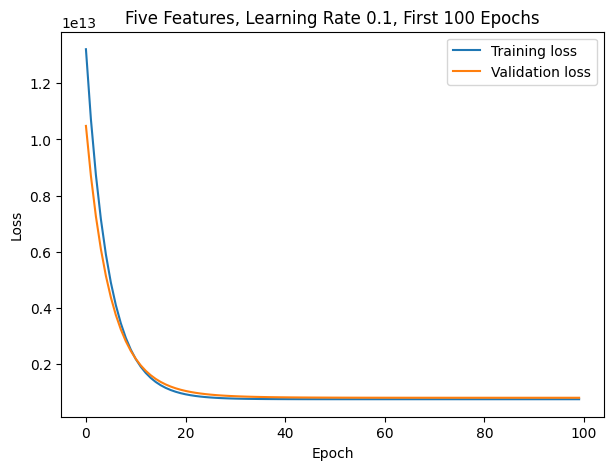

In [10]:
plt.figure(figsize=(7, 5))
plt.plot(best_train_curve[:100], label="Training loss")
plt.plot(best_val_curve[:100], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Five Features, Learning Rate " + str(best_lr) + ", First 100 Epochs")
plt.legend()
plt.show()

In [11]:
columns = [c for c in df.columns if c != "price"]
print("Inputs:", columns)
X_train, X_val, y_train, y_val = prepare(columns)

best_val = 1e30
for lr in learning_rates:
    train_curve, val_curve, log = train_housing(X_train, X_val, y_train, y_val, lr)
    print()
    print("Learning rate", lr)
    print("  epoch   train loss     validation loss   validation R2")
    for epoch, tl, vl, r2 in log:
        print(f"  {epoch:5d}   {tl:.4e}   {vl:.4e}      {r2:.4f}")
    if log[-1][2] < best_val:
        best_val = log[-1][2]
        best_lr = lr
        best_log = log
        best_train_curve = train_curve
        best_val_curve = val_curve

print()
print("Best learning rate:", best_lr)
print("Final train loss:", best_log[-1][1])
print("Final validation loss:", best_log[-1][2])
print("Final validation R2:", best_log[-1][3])

Inputs: ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']

Learning rate 0.1
  epoch   train loss     validation loss   validation R2
    500   5.4424e+11   6.2086e+11      0.6464
   1000   5.4424e+11   6.2086e+11      0.6464
   1500   5.4424e+11   6.2086e+11      0.6464
   2000   5.4424e+11   6.2086e+11      0.6464
   2500   5.4424e+11   6.2086e+11      0.6464
   3000   5.4424e+11   6.2086e+11      0.6464
   3500   5.4424e+11   6.2086e+11      0.6464
   4000   5.4424e+11   6.2086e+11      0.6464
   4500   5.4424e+11   6.2086e+11      0.6464
   5000   5.4424e+11   6.2086e+11      0.6464

Learning rate 0.01
  epoch   train loss     validation loss   validation R2
    500   5.4489e+11   6.2650e+11      0.6432
   1000   5.4424e+11   6.2098e+11      0.6464
   1500   5.4424e+11   6.2087e+11      0.6464
   2000   5.4424e+11   6.2086e+

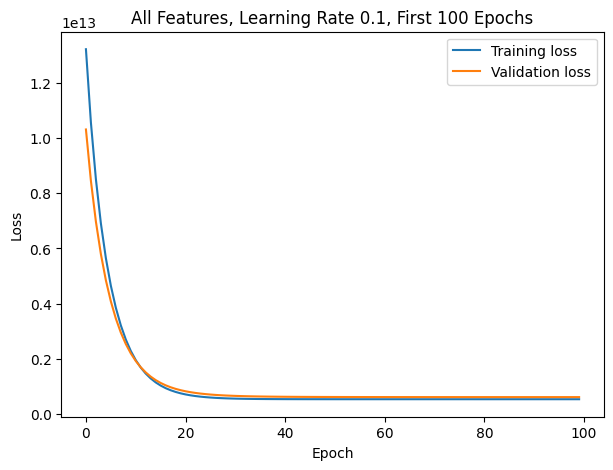

In [12]:
plt.figure(figsize=(7, 5))
plt.plot(best_train_curve[:100], label="Training loss")
plt.plot(best_val_curve[:100], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("All Features, Learning Rate " + str(best_lr) + ", First 100 Epochs")
plt.legend()
plt.show()